### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd

import sys
sys.path.append("../functions/")
import compare_inter_exp_sim.venturelli2018 as venturelli2018

import compare_inter_exp_sim.correlation as correlation


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
signal_exp = venturelli2018.load_experimental_results()

In [4]:
signal_exp

member_second  member_main
BH             BH            -0.9118
               BO            -0.2145
               BT            -0.2718
               BU            -0.2275
               BV            -0.1294
                               ...  
PC             DP            -0.9771
               EL            -0.9041
               ER            -0.8171
               FP            -0.4053
               PC            -0.6217
Name: experimental, Length: 144, dtype: float64

In [5]:
simulation_dict = venturelli2018.load_simulation_results()


## Cooperation and competition - SteadierCom

In [6]:
results_corr_df,results_corr_member_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

steadycom
steadiercom
smetana


In [7]:
results_corr_df_bh = results_corr_df.copy()
results_corr_df_bh["rank"] = results_corr_df_bh["p-value"].rank()
results_corr_df_bh["p-value BH critical"] = (results_corr_df_bh["rank"]/results_corr_df_bh.shape[0])*0.05

results_corr_df_bh["pass BH test"] = results_corr_df_bh["p-value"]<results_corr_df_bh["p-value BH critical"]


In [8]:
results_corr_member_df_bh = results_corr_member_df.copy()
results_corr_member_df_bh["rank"] = results_corr_member_df_bh["p-value"].rank()
results_corr_member_df_bh["p-value BH critical"] = (results_corr_member_df_bh["rank"]/results_corr_member_df_bh.shape[0])*0.05
results_corr_member_df_bh["pass BH test"] = results_corr_member_df_bh["p-value"]<results_corr_member_df_bh["p-value BH critical"]


In [9]:
results_corr_df_bh = results_corr_df_bh.dropna()
results_corr_df_bh.query("`pass BH test`")

r  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate -0.200255   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.207101   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.186904   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.002359   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.001662   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.004538   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate       110.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate            34.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   2.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate   3.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.005556   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.002778   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate             0.008333   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
                               SteadierCom - Fixed growth & abundance frequency*mass_rate          True

In [10]:
results_corr_df_bh.query("r > 0").xs("coop",drop_level=False).sort_index() # HIGHER THRESHOLD

r  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.106460   
                               SteadierCom - Fixed growth             frequency*mass_rate  0.101281   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.100983   
             steadycom         SteadyCom - Nothing fixed              rate?                0.046142   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.105967   
                               SteadierCom - Fixed growth             frequency*mass_rate  0.135953   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.125172   
             steadycom         SteadyCom - Nothing fixed              rate?                0.544815   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
                               SteadierCom - Fixed growth             frequency*mass_rate       104.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate       110.0   
             steadycom         SteadyCom - Nothing fixed              rate?                      83.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
                               SteadierCom - Fixed growth             frequency*mass_rate            40.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate            34.0   
             steadycom         SteadyCom - Nothing fixed              rate?                          61.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   7.0   
                               SteadierCom - Fixed growth             frequency*mass_rate   9.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate   8.0   
             steadycom         SteadyCom - Nothing fixed              rate?                13.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.019444   
                               SteadierCom - Fixed growth             frequency*mass_rate             0.025000   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate             0.022222   
             steadycom         SteadyCom - Nothing fixed              rate?                           0.036111   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
coop         steadiercom       SteadierCom - Fixed abundance          frequency*ma

In [11]:
results_corr_df_bh.query("`p-value` < 0.05 & r < 0").xs("comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate -0.200255   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate -0.158150   
             steadycom         SteadyCom - Nothing fixed              rate?               -0.158540   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.002359   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.016328   
             steadycom         SteadyCom - Nothing fixed              rate?                0.030129   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate       110.0   
             steadycom         SteadyCom - Nothing fixed              rate?                      90.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate            34.0   
             steadycom         SteadyCom - Nothing fixed              rate?                          54.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   2.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate   4.0   
             steadycom         SteadyCom - Nothing fixed              rate?                 5.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.005556   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate             0.011111   
             steadycom         SteadyCom - Nothing fixed              rate?                           0.013889   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
                               SteadierCom - Fixed growth & abundance frequency*mass_rate         False  
             steadycom         SteadyCom - Nothing fixed              rate?                       False

In [12]:
results_corr_df_bh.query("`p-value` < 0.05 & r > 0").xs("coop-comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric                          
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.207101   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.186904   
             steadycom         SteadyCom - Nothing fixed              rate?                0.154948   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.001662   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.004538   
             steadycom         SteadyCom - Nothing fixed              rate?                0.034068   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate       110.0   
             steadycom         SteadyCom - Nothing fixed              rate?                      90.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate            34.0   
             steadycom         SteadyCom - Nothing fixed              rate?                          54.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate   3.0   
             steadycom         SteadyCom - Nothing fixed              rate?                 6.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.002778   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate             0.008333   
             steadycom         SteadyCom - Nothing fixed              rate?                           0.016667   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
                               SteadierCom - Fixed growth & abundance frequency*mass_rate          True  
             steadycom         SteadyCom - Nothing fixed              rate?                       False

### Member-wise correlation with experimental data
None of the results are significant...

In [13]:
results_corr_member_df_bh = results_corr_member_df_bh.dropna()
results_corr_member_df_bh.query("`pass BH test`")

,,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,member,,,,,,,


In [14]:
results_corr_member_df_bh.query("`p-value` < 0.05 and r > 0").xs("coop",drop_level=False).sort_index()

,,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,member,,,,,,,
coop,steadiercom,SteadierCom - Fixed growth,frequency*mass_rate,BH,0.511682,0.040077,11.0,1.0,12.0,0.002778,False


In [15]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r < 0").xs("comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BU     -0.555556   
                                                                                          BV     -0.555556   
                                                                                          ER     -0.547723   
                               SteadierCom - Fixed growth             frequency*mass_rate BO     -0.636364   
                                                                                          BT     -0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO     -0.555556   
                                                                                          BV     -0.555556   
             steadycom         SteadyCom - Nothing fixed              rate?               EL     -0.611111   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BU      0.028609   
                                                                                          BV      0.028609   
                                                                                          ER      0.045056   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.005707   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.028609   
                                                                                          BV      0.028609   
             steadycom         SteadyCom - Nothing fixed              rate?               EL      0.024741   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BU            10.0   
                                                                                          BV            10.0   
                                                                                          ER            10.0   
                               SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            10.0   
                                                                                          BV            10.0   
             steadycom         SteadyCom - Nothing fixed              rate?               EL             9.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BU                 2.0   
                                                                                          BV                 2.0   
                                                                                          ER                 2.0   
                               SteadierCom - Fixed growth             frequency*mass_rate BO                 1.0   
                                                                                      

In [16]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r > 0").xs("coop-comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BO      0.555556   
                                                                                          BU      0.644444   
                                                                                          BV      0.511111   
                                                                                          ER      0.547723   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.636364   
                                                                                          BT      0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.644444   
                                                                                          BU      0.644444   
                                                                                          BV      0.511111   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BO      0.028609   
                                                                                          BU      0.009148   
                                                                                          BV      0.046623   
                                                                                          ER      0.045056   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.005707   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.009148   
                                                                                          BU      0.009148   
                                                                                          BV      0.046623   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BO            10.0   
                                                                                          BU            10.0   
                                                                                          BV            10.0   
                                                                                          ER            10.0   
                               SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            10.0   
                                                                                          BU            10.0   
                                                                                          BV            10.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate BO                 2.0   
                                                                                          BU          

(<Figure size 640x480 with 2 Axes>,
 <Axes: title={'center': ' \n  #simulated=40, #not simulated=8'}, xlabel='gLV', ylabel='coop-comp\n normalized frequency*mass_rate'>,
 <Axes: xlabel='experimental', ylabel='Density'>,
 array([('BO', 'BO'), ('PC', 'BO'), ('BU', 'BU'), ('PC', 'BU'),
        ('BV', 'BV'), ('PC', 'BV'), ('BT', 'BT'), ('PC', 'BT')],
       dtype=object))

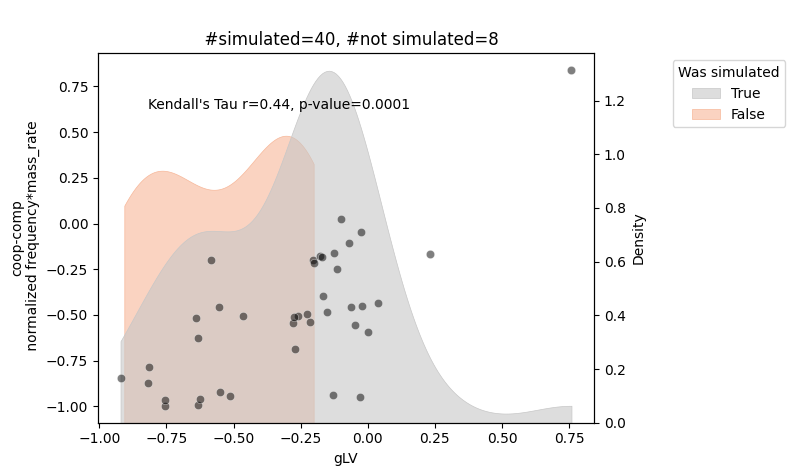

In [17]:
signal_exp_best = signal_exp.loc[(slice(None),["BO","BU","BV","BT"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]

correlation.make_scatterplot(simulated_res,signal_exp_best,coop_or_comp="coop-comp",metric="frequency*mass_rate",ax=None,xlabel="gLV",ylabel="coop-comp\n normalized frequency*mass_rate",title="",include_legend=True)

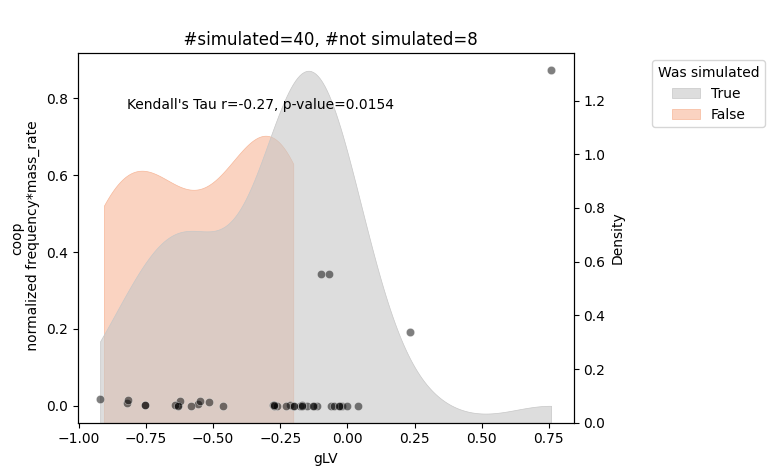

In [ ]:
signal_exp_best = signal_exp.loc[(slice(None),["BO","BU","BV","BT"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]

fig,ax, ax_twin,labels = correlation.make_scatterplot(simulated_res,
                                                      signal_exp_best,
                                                      coop_or_comp="coop",
                                                      metric="frequency*mass_rate",
                                                      ax=None,
                                                      xlabel="gLV",
                                                      ylabel="coop\n normalized frequency*mass_rate",
                                                      title="",
                                                      include_legend=True)

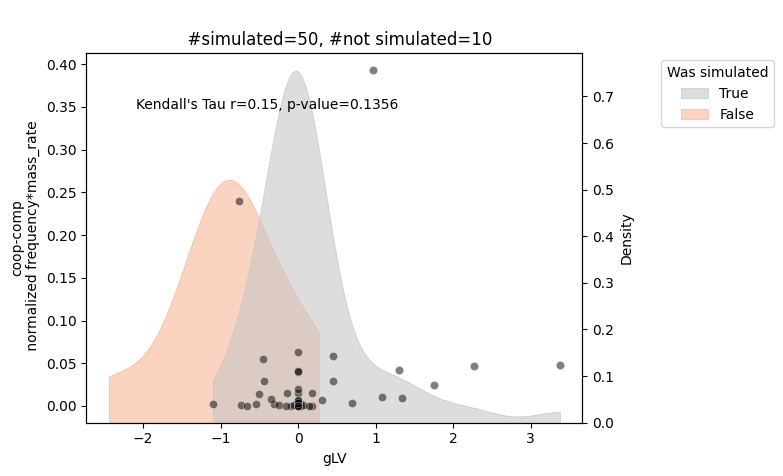

In [25]:
signal_exp_best = signal_exp.loc[(slice(None),["EL","ER","CA","CH","BH"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]

fig,ax, ax_twin,labels =correlation.make_scatterplot(simulated_res,signal_exp_best,coop_or_comp="coop",metric="frequency*mass_rate",ax=None,xlabel="gLV",ylabel="coop-comp\n normalized frequency*mass_rate",title="",include_legend=True)

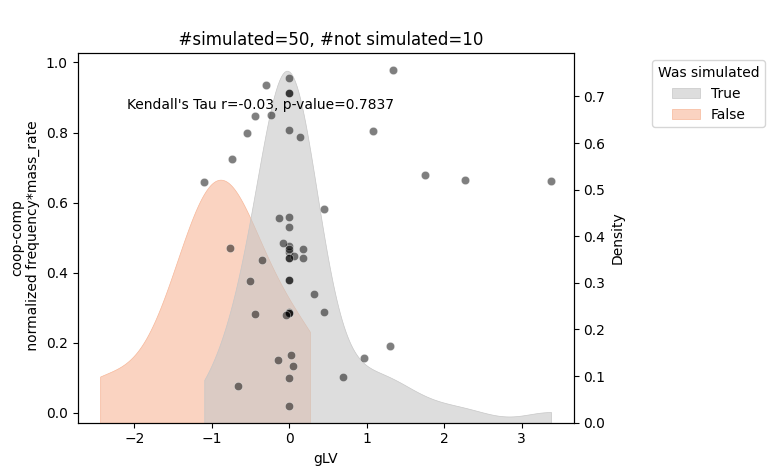

In [27]:
signal_exp_best = signal_exp.loc[(slice(None),["EL","ER","CA","CH","BH"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]

fig,ax, ax_twin,labels = correlation.make_scatterplot(simulated_res,signal_exp_best,coop_or_comp="comp",metric="frequency*mass_rate",ax=None,xlabel="gLV",ylabel="coop-comp\n normalized frequency*mass_rate",title="",include_legend=True)

#### SteadierCom - scatterplot - frequency*mass_rate

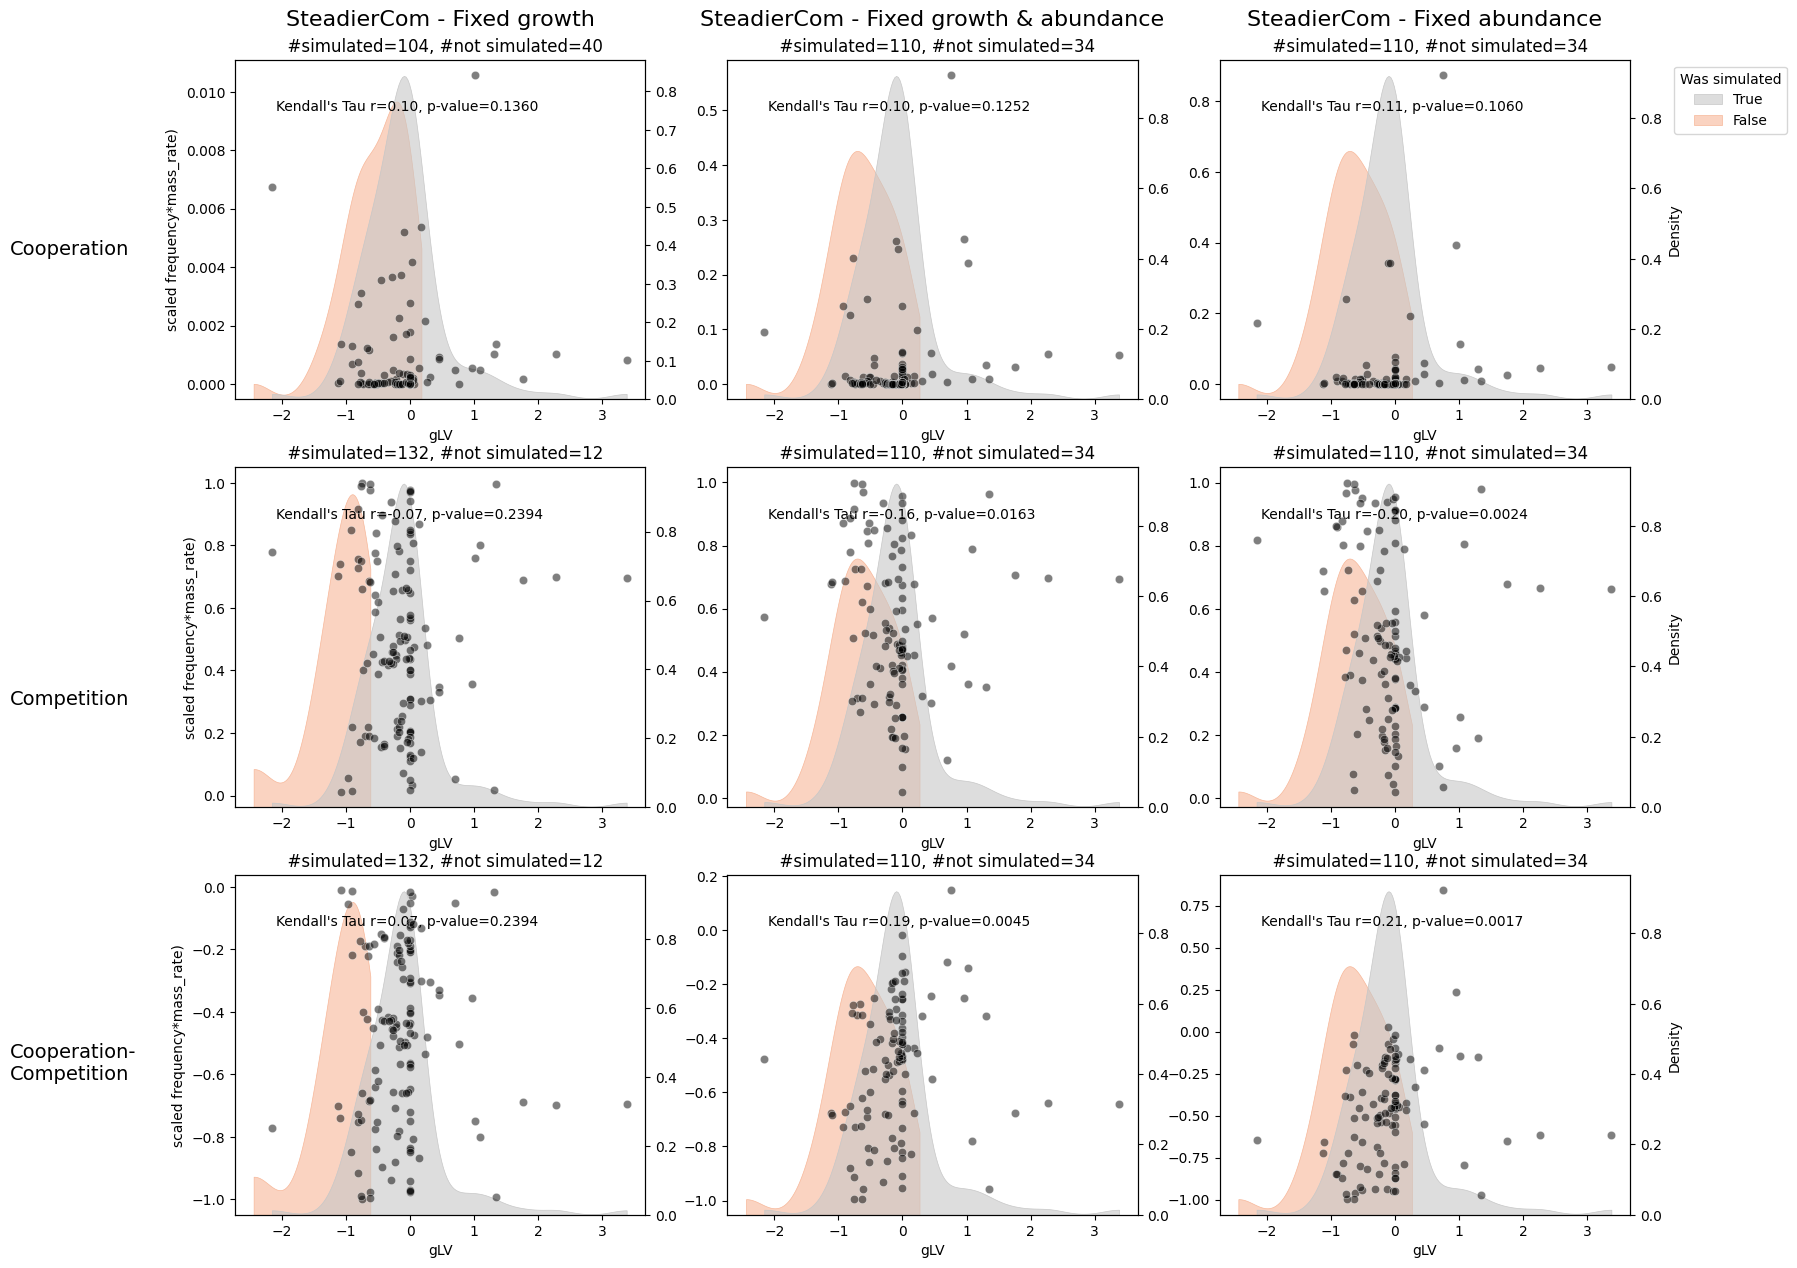

In [28]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency*mass_rate",
                                                                                )

<Axes: xlabel='member_second'>

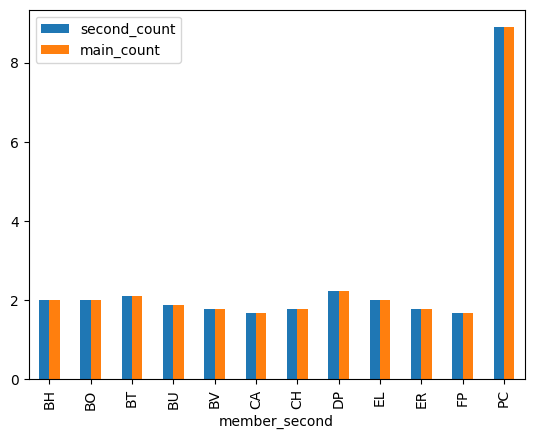

In [29]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")

#### SteadyCom - scatterplot - rate?

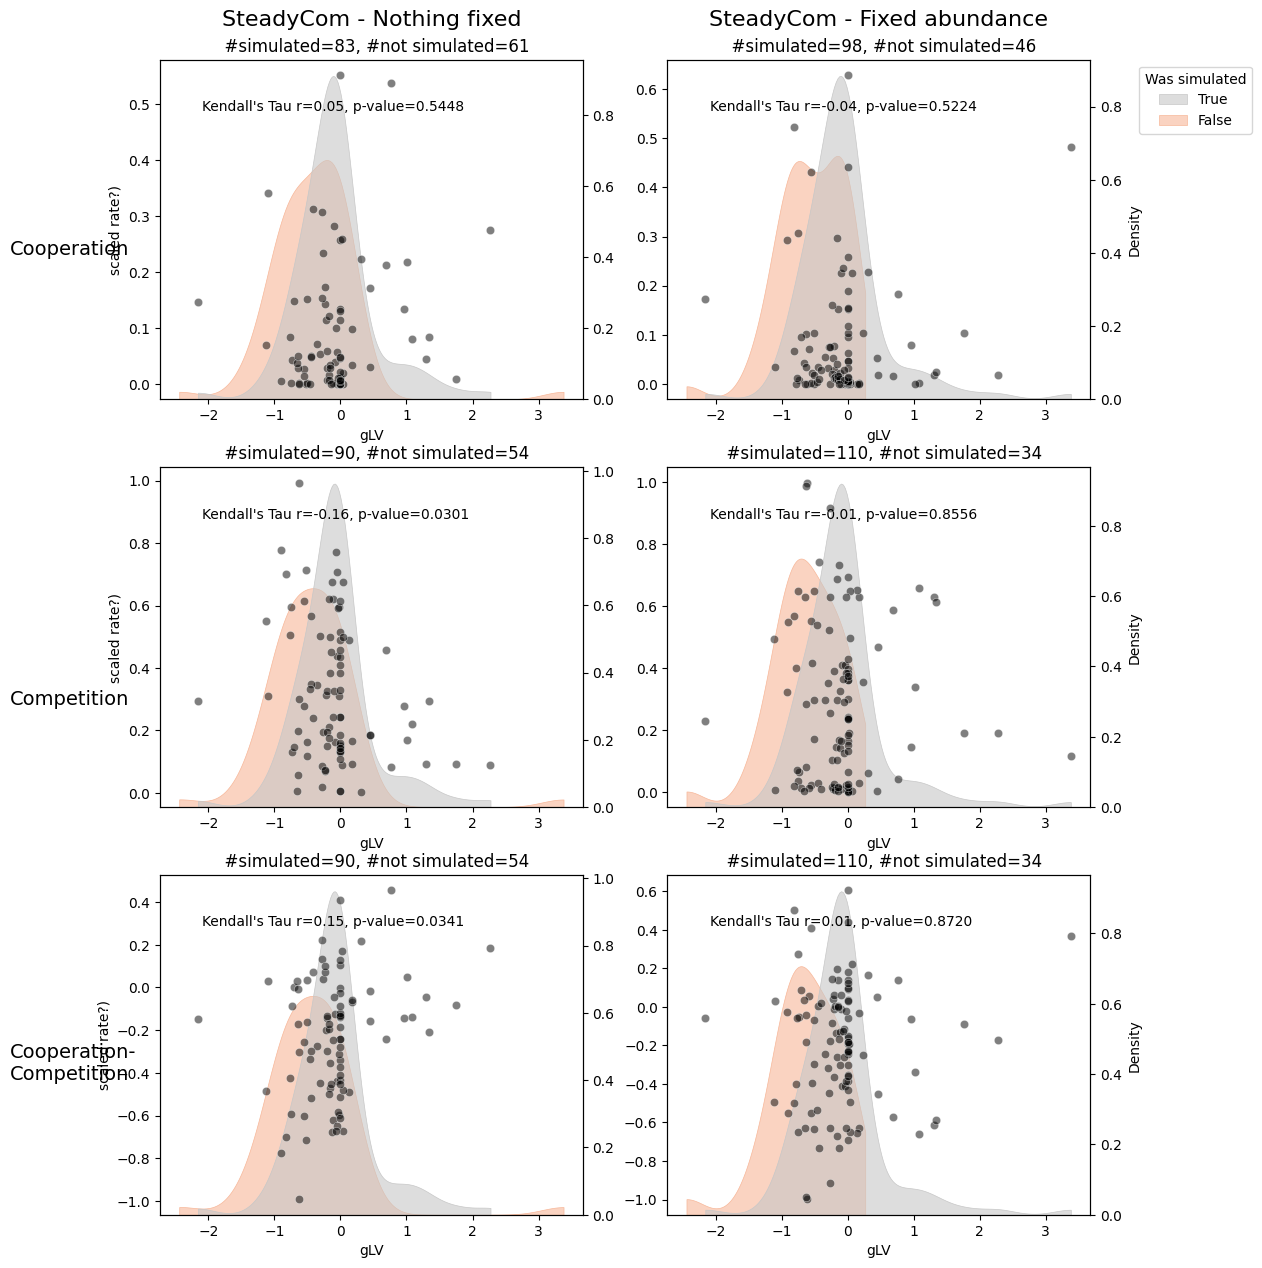

In [30]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadycom",
                                                                                 metric="rate?")

<Axes: xlabel='member_second'>

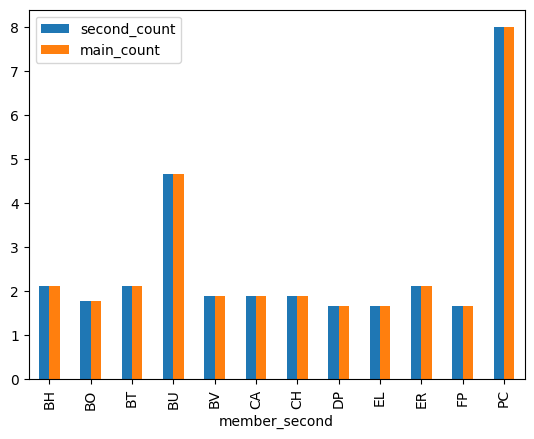

In [31]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")